# Reading the Geobase file:

In [7]:
import geopandas as gpd
import pandas as pd
import os

RAW = "../raw/geobase.json"          # the downloaded file (stays out of GitHub as it's 41.1 MB)
streets = gpd.read_file(RAW)         # reads the whole street network
print("rows:", len(streets))
print("columns:", streets.columns.tolist())
print("coordinate system:", streets.crs)
streets.head(3)

rows: 48034
columns: ['ID_TRC', 'DEB_GCH', 'FIN_GCH', 'ARR_GCH', 'SENS_CIR', 'CLASSE', 'LIE_VOIE', 'TYP_VOIE', 'DIR_VOIE', 'NOM_VOIE', 'DEB_DRT', 'FIN_DRT', 'ARR_DRT', 'LIM_GCH', 'LIM_DRT', 'POSITION', 'ODONYME', 'geometry']
coordinate system: EPSG:4326


,ID_TRC,DEB_GCH,FIN_GCH,ARR_GCH,SENS_CIR,CLASSE,LIE_VOIE,TYP_VOIE,DIR_VOIE,NOM_VOIE,DEB_DRT,FIN_DRT,ARR_DRT,LIM_GCH,LIM_DRT,POSITION,ODONYME,geometry
0,1010001,12320,12340,Ahuntsic-Cartierville,0,0,NaN,avenue,NaN,Adhémar-Mailhiot,12323,12335,Ahuntsic-Cartierville,Montréal,Montréal,5,Avenue Adhémar-Mailhiot,"LINESTRING (-73.7408 45.51896, -73.74087 45.51..."
1,1010004,5530,5570,Ahuntsic-Cartierville,0,0,NaN,place,NaN,D'Aiguillon,5475,5625,Ahuntsic-Cartierville,Montréal,Montréal,5,Place D'Aiguillon,"LINESTRING (-73.70624 45.52765, -73.70629 45.5..."
2,1010005,7750,7830,Ahuntsic-Cartierville,0,0,NaN,avenue,NaN,Albert-LeSage,7745,7805,Ahuntsic-Cartierville,Montréal,Montréal,5,Avenue Albert-LeSage,"LINESTRING (-73.73715 45.52446, -73.73721 45.5..."


# Cutting it to my study area for A3

In [8]:
# Step 2: keeping only the segments inside the study box for Central Montreal
WEST, EAST = -73.615, -73.555        # the same box as the stops, in degrees
SOUTH, NORTH = 45.495, 45.535

if streets.crs is None or streets.crs.to_epsg() != 4326:
    streets = streets.to_crs("EPSG:4326")   # make sure we are in degrees, like the box

before = len(streets)
box_streets = streets.cx[WEST:EAST, SOUTH:NORTH].copy()   # segments that touch the box
print("segments before:", before, "| inside the box:", len(box_streets))

segments before: 48034 | inside the box: 3253


In [9]:
# Step 3: keeping only the columns we need, then checking them
keep = ["ID_TRC", "ODONYME", "CLASSE", "geometry"]    # segment ID, full street name, road class, shape
missing = [c for c in keep if c not in box_streets.columns]
print("missing columns:", missing)                    # should be an empty list []

box_streets = box_streets[keep].copy()
print("segments:", len(box_streets))
print("IDs all unique:", box_streets["ID_TRC"].is_unique)    # should be True
print("segments with no name:", box_streets["ODONYME"].isna().sum())
print("shape types:", sorted(box_streets.geom_type.unique()))
print(box_streets["CLASSE"].value_counts().sort_index())    # 0 = local streets, 6 and 7 = main roads

missing columns: []
segments: 3253
IDs all unique: True
segments with no name: 0
shape types: ['LineString']
CLASSE
0    1671
1      42
2       5
4      61
5     499
6     494
7     437
8      44
Name: count, dtype: int64


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

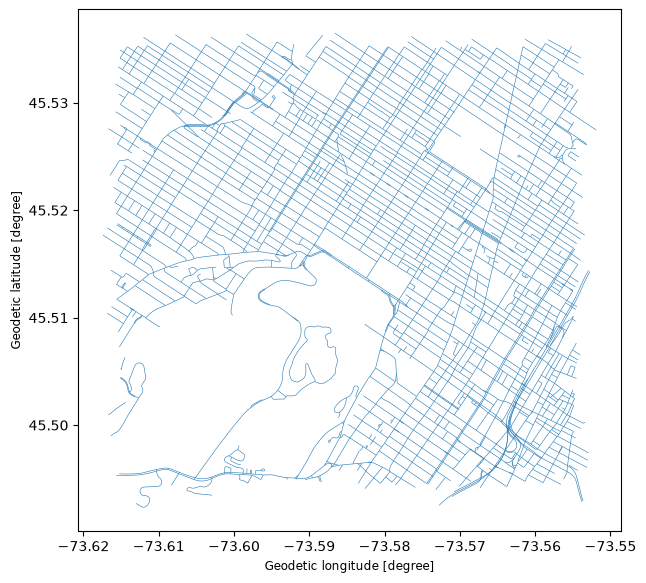

In [10]:
# Step 4: a quick picture of the street network
box_streets.plot(figsize=(7, 7), linewidth=0.4)

# Match each stop to its street:

In [11]:
# Step 5a: reading the stops and put stops and streets in metres
stops = gpd.read_file("../data/potholes_2024_2025.geojson")     # 21,205 stops (in degrees)
print("stops read:", len(stops))
stops["month"] = pd.to_datetime(stops["date"]).dt.month          # 1 = January ... 5 = May

# the street segments again, this time keeping POSITION so we can leave out tunnels (GPS data is very inaccurate for underground)
targets = streets.cx[WEST:EAST, SOUTH:NORTH][["ID_TRC", "ODONYME", "CLASSE", "POSITION", "geometry"]].copy()
targets = targets[~targets["POSITION"].isin([7, 8, 9])].copy()   # 7 to 9 are underground tunnels
targets["ODONYME"] = targets["ODONYME"].str.strip()              # remove the trailing space in street names
print("street segments to match against:", len(targets))

stops_m = stops.to_crs("EPSG:2950")      # metres (Montréal's system), so distances mean something
targets_m = targets.to_crs("EPSG:2950")

stops read: 21205
street segments to match against: 3237


In [12]:
# Step 5b: finding thr nearest street for each stop (up to 100 m away), then looking at the distances
nearest = gpd.sjoin_nearest(
    stops_m, targets_m[["ID_TRC", "ODONYME", "geometry"]],
    how="left", max_distance=100, distance_col="dist_m")
nearest = nearest[~nearest.index.duplicated(keep="first")]       # a tie between two streets keeps one (Lab 5, recipe 8)
print("rows:", len(nearest), "(should equal", len(stops), ")")
for m in (5, 10, 15, 20, 30, 50, 100):
    share = (nearest["dist_m"] <= m).mean() * 100
    print(f"within {m:>3} m: {share:5.1f}% of stops")

rows: 21205 (should equal 21205 )
within   5 m:  49.4% of stops
within  10 m:  78.4% of stops
within  15 m:  90.6% of stops
within  20 m:  95.2% of stops
within  30 m:  98.7% of stops
within  50 m:  99.9% of stops
within 100 m: 100.0% of stops


**Keeping the matches within 30 m, count per segment, then check the totals.**

In [13]:
# Step 5c: keep matches within MAX_M metres, then count per street segment
MAX_M = 30                                               # how far from a street a stop may be and still count as on it
assigned = nearest[nearest["dist_m"] <= MAX_M].copy()    # stops matched to a street
unmatched = nearest[~(nearest["dist_m"] <= MAX_M)]       # too far from every street: kept in the totals, not matched

# one column per year and month, for example m24_3 = stops in March 2024
counts = pd.crosstab(assigned["ID_TRC"], [assigned["year"], assigned["month"]])
counts.columns = [f"m{y % 100}_{m}" for y, m in counts.columns]
ALL = [f"m{yy}_{m}" for yy in (24, 25) for m in range(1, 6)]
counts = counts.reindex(columns=ALL, fill_value=0)       # make sure every month column exists

print("stops read:", len(stops))
print("matched to a street:", len(assigned))
print("not matched:", len(unmatched))
print("matched + not matched =", len(assigned) + len(unmatched), "(must equal", len(stops), ")")
print("segment counts add up to matched:", int(counts.values.sum()) == len(assigned))
print("segments with at least one stop:", len(counts), "of", len(targets))

stops read: 21205
matched to a street: 20931
not matched: 274
matched + not matched = 21205 (must equal 21205 )
segment counts add up to matched: True
segments with at least one stop: 1735 of 3237


# Check: Do the busiest segments make sense?

In [14]:
# Step 6: checking for the five segments with the most stops
top = counts.sum(axis=1).sort_values(ascending=False).head(5)
print(targets.set_index("ID_TRC").loc[top.index, "ODONYME"].to_frame().assign(stops=top))

                                    ODONYME  stops
ID_TRC                                            
1140118                           Rue Clark    430
1604073  Chemin de la Côte-Sainte-Catherine    401
4008731        Boulevard De Maisonneuve Est    248
1380905                Rue Sherbrooke Ouest    233
1604140  Chemin de la Côte-Sainte-Catherine    224


# Making a table of streets with their stop counts:

In [15]:
# Step 7: one table of all street segments, with their counts
seg = targets[["ID_TRC", "ODONYME", "CLASSE", "geometry"]].merge(
    counts.reset_index(), on="ID_TRC", how="left")       # keeps all 3,237 segments
seg[ALL] = seg[ALL].fillna(0).astype(int)                 # no stops means 0, not blank
seg["y2024"] = seg[[c for c in ALL if c.startswith("m24_")]].sum(axis=1)
seg["y2025"] = seg[[c for c in ALL if c.startswith("m25_")]].sum(axis=1)
seg["total"] = seg["y2024"] + seg["y2025"]
seg = seg.rename(columns={"ID_TRC": "id", "ODONYME": "name", "CLASSE": "cls"})   # short names for the web page

print("segments:", len(seg))
print("stops across all segments:", seg["total"].sum(), "(must equal matched:", len(assigned), ")")
print("2024:", seg["y2024"].sum(), "| 2025:", seg["y2025"].sum())
print("segments with no stops:", (seg["total"] == 0).sum())

segments: 3237
stops across all segments: 20931 (must equal matched: 20931 )
2024: 8626 | 2025: 12305
segments with no stops: 1502


# Street file in Degrees:

In [16]:
# Step 8: writing the streets file in degrees, with 6 decimals, and checking its size
OUT_STREETS = "../data/streets_central.geojson"
seg.to_crs("EPSG:4326").to_file(OUT_STREETS, driver="GeoJSON", COORDINATE_PRECISION=6)
print("saved:", OUT_STREETS, "|", round(os.path.getsize(OUT_STREETS) / 1_000_000, 2), "MB")

saved: ../data/streets_central.geojson | 1.41 MB


# The final check:

In [18]:
# Step 9: read the file back and check it, printing the numbers behind every check
back = gpd.read_file(OUT_STREETS)
problems = []

def report(ok, label, detail):
    # prints one line per check: PASS or FAIL, then the numbers behind it
    print(("PASS  " if ok else "FAIL  ") + label + ": " + detail)
    if not ok:
        problems.append(label + ": " + detail)

# check 1: the file has as many segments as the table we wrote
report(len(back) == len(seg), "segments in the file",
       f"{len(back)} in the file, {len(seg)} expected")

# check 2: the coordinate system is longitude and latitude
epsg = back.crs.to_epsg() if back.crs is not None else None
report(epsg == 4326, "coordinate system", f"EPSG:{epsg} (expected 4326)")

# check 3: the counts add up to the stops matched in Step 4
total_in_file = int(back["total"].sum())
report(total_in_file == len(assigned), "stops across all segments",
       f"{total_in_file} in the file, {len(assigned)} matched in Step 4")

# check 4: the two years add up to the total
y24, y25 = int(back["y2024"].sum()), int(back["y2025"].sum())
report(y24 + y25 == total_in_file, "2024 + 2025 = total",
       f"{y24} + {y25} = {y24 + y25}, total is {total_in_file}")

# check 5: the month columns add up to the total
month_sum = int(back[ALL].sum().sum())
report(month_sum == total_in_file, "month columns add up",
       f"{month_sum} across {len(ALL)} month columns, total is {total_in_file}")

# check 6: every stop is accounted for (matched + not matched = stops read)
accounted = len(assigned) + len(unmatched)
report(accounted == len(stops), "every stop accounted for",
       f"{len(assigned)} matched + {len(unmatched)} not matched = {accounted}, stops read {len(stops)}")

# check 7: all the fields the page needs are there
need = ["id", "name", "cls", "total", "y2024", "y2025"] + ALL
missing = [c for c in need if c not in back.columns]
report(not missing, "fields present",
       f"{len(need) - len(missing)} of {len(need)} found" + (f", missing {missing}" if missing else ""))

# check 8: street names have no spaces at the end
untrimmed = int((back["name"] != back["name"].str.strip()).sum())
report(untrimmed == 0, "street names trimmed", f"{untrimmed} names with spaces at the end")

# check 9: the file is small enough for a phone
mb = os.path.getsize(OUT_STREETS) / 1_000_000
report(mb <= 5, "file size", f"{mb:.2f} MB (limit about 5 MB)")

# check 10: every shape is a line
types = sorted(back.geom_type.unique())
report(types == ["LineString"], "shape types", str(types))

# the verdict, then two facts worth knowing
print()
print("All checks passed" if not problems else "Not yet:\n- " + "\n- ".join(problems))
print("Segments with at least one stop:", int((back["total"] > 0).sum()), "of", len(back))
busiest = back.sort_values("total", ascending=False).iloc[0]
print("Busiest segment:", busiest["name"], "with", int(busiest["total"]), "stops")

PASS  segments in the file: 3237 in the file, 3237 expected
PASS  coordinate system: EPSG:4326 (expected 4326)
PASS  stops across all segments: 20931 in the file, 20931 matched in Step 4
PASS  2024 + 2025 = total: 8626 + 12305 = 20931, total is 20931
PASS  month columns add up: 20931 across 10 month columns, total is 20931
PASS  every stop accounted for: 20931 matched + 274 not matched = 21205, stops read 21205
PASS  fields present: 16 of 16 found
PASS  street names trimmed: 0 names with spaces at the end
PASS  file size: 1.41 MB (limit about 5 MB)
PASS  shape types: ['LineString']

All checks passed
Segments with at least one stop: 1735 of 3237
Busiest segment: Rue Clark with 430 stops


# Additional Tunnel Check:

In [19]:
# Tunnel check: would any stops have been matched to a tunnel if we had left tunnels in?
all_segs = streets.cx[WEST:EAST, SOUTH:NORTH][["ID_TRC", "ODONYME", "POSITION", "geometry"]].to_crs("EPSG:2950")
print("tunnel segments in your box:", all_segs["POSITION"].isin([7, 8, 9]).sum())

# nearest street for every stop, this time with tunnels left in
test = gpd.sjoin_nearest(stops_m, all_segs, how="left", max_distance=30, distance_col="dist_m")
test = test[~test.index.duplicated(keep="first")]        # a tie between two streets keeps one

# the stops whose nearest street is a tunnel
in_tunnel = test[test["POSITION"].isin([7, 8, 9])]
print("stops nearest to a tunnel:", len(in_tunnel), "of", len(stops_m))
print(in_tunnel["ODONYME"].str.strip().value_counts().head(10))

tunnel segments in your box: 16
stops nearest to a tunnel: 159 of 21205
ODONYME
Route 136          113
Voie Non-nommée     46
Name: count, dtype: int64
